# Solar Filament Segmentation Challenge 2026: end-to-end pipeline

**Øyvind Andre Roth** · [competition](https://www.kaggle.com/competitions/filament-segmentation-2026) · code: [github.com/oyvindar/solar-filament-2026](https://github.com/oyvindar/solar-filament-2026)

The score is Panoptic Quality (PQ) pooled over every (annotator, image) pair. For predictions that share no pixel, its denominator is `0.5 * (R * #predictions + #GT)` no matter which predictions match (R = annotators of the image). Each predicted filament therefore contributes on its own, and keeping it pays off exactly when its expected matched IoU, averaged over annotators, exceeds `PQ / 2`. The pipeline:

1. **Stage 1** (GPU): U-Nets predict the probability that a random annotator marks a pixel.
2. **Stage 2** (CPU): candidate filaments are the connected components of that map at 15 thresholds (a component tree); a gradient-boosted model estimates each candidate's expected matched IoU; a tree dynamic program picks, per image, the non-overlapping set that maximises the PQ objective exactly.
3. **Stage 3** (GPU, optional): every selected filament is re-segmented by a small U-Net in a crop around it.

| | out-of-fold PQ (707 training images, 5 date-grouped folds) | public leaderboard |
|---|---|---|
| stage-1 maps, connected components at threshold 0.35 (>= 500 px) | 0.414 | - |
| stage 2: component tree + learned expected IoU + exact selection | 0.434 | 0.37 |
| stage 3: + crop refiner (threshold chosen on the other folds) | 0.438 | 0.37 |
| one annotator scored against the others (296 images) | 0.340 | - |

**How to run.** `FSC_MODE=reuse` (default) takes the stage-1 probability maps of the published Kaggle runs (attach the ten `fsc26-unet-*` notebooks as inputs, or point `FSC_STAGE1` at their outputs) and recomputes stages 2 and 3; the stage-3 crops of the published refiner run are reused only if they were made from identical seeds. `FSC_MODE=full` trains the ten U-Nets and the refiner first (about 8 h on 2 x T4, internet needed for the ImageNet encoder weights).

Only the competition's training images and annotations are used for training; inference uses only the given test image.

In [1]:
import os, sys, glob, json, time, pickle, shutil, subprocess
from pathlib import Path

ON_KAGGLE = os.path.exists("/kaggle/input")
candidates = [Path.cwd(), Path.cwd().parent, Path("/kaggle/working/solar-filament-2026")]
REPO = next((p for p in candidates if (p / "src" / "fsc" / "__init__.py").exists()), None)
if REPO is None:  # on Kaggle: use an attached copy of the repository, else clone it
    REPO = Path("/kaggle/working/solar-filament-2026")
    attached = glob.glob("/kaggle/input/**/src/fsc/__init__.py", recursive=True)
    if attached:
        shutil.copytree(Path(attached[0]).parents[2], REPO, dirs_exist_ok=True)
    else:
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/oyvindar/solar-filament-2026", str(REPO)], check=True)
sys.path.insert(0, str(REPO / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from fsc import data as fdata, extract as fx, scorer as sc, select as fs, predict as fp, metric as fm, refine as frf, plots
print("repository:", REPO)

repository: <root>\solar-filament-2026


In [2]:
MODE = os.environ.get("FSC_MODE", "reuse")
INPUT = Path(os.environ.get("FSC_INPUT", "/kaggle/input" if ON_KAGGLE else REPO.parent / "filament-segmentation-2026"))
DATA_ROOT = Path(glob.glob(str(INPUT / "**" / "MAGFiLO_1.0_Annotations_kaggle2026_train.json"), recursive=True)[0]).parents[1]
WORK = Path(os.environ.get("FSC_WORK", "/kaggle/working/work" if ON_KAGGLE else REPO.parent / "work"))
PUBLISHED = Path("/kaggle/input") if ON_KAGGLE else WORK / "kaggle_out"  # outputs of the published Kaggle runs
STAGE1_ROOT = Path(os.environ.get("FSC_STAGE1", WORK / "stage1" if MODE == "full" else PUBLISHED))
STAGE3_ROOT = Path(os.environ.get("FSC_STAGE3", PUBLISHED))
NW = min(4, os.cpu_count() or 1)
ENCODERS = ("resnet34", "resnet50")
WORK.mkdir(parents=True, exist_ok=True)

C = fdata.Coco(str(DATA_ROOT))
folds = fdata.load_folds(str(REPO))
fold_of = dict(zip(folds["stem"], folds["fold"]))
GT = fm.gt_frame_from_coco(C.raw)
print(f"mode {MODE} | {len(C.stems)} training images, {len(C.test_stems)} test images, {len(GT)} annotated filaments "
      f"({len(C.raw['images'])} annotator x image records) | workers {NW}")
print(folds.groupby("fold").agg(images=("stem", "size"), dates=("date", "nunique")).T.to_string())

mode reuse | 707 training images, 180 test images, 8199 annotated filaments (1154 annotator x image records) | workers 4
fold      0    1    2    3    4
images  142  142  141  141  141
dates   131  132  131  131  131


## Stage 1: soft-label U-Nets

Target: the share of annotators who marked each pixel. Input: two channels, the disk-standardised H-alpha intensity and a log flat-field ratio (image over its 24-px Gaussian blur), at native resolution. Encoders: timm ResNet34 (18 epochs) and ResNet50 (22 epochs), ImageNet weights; 1024 x 1024 random crops, flips and 90-degree rotations, brightness jitter; loss BCE + 0.5 soft Dice; AdamW with cosine decay; exponential moving average of the weights. Prediction: full 2048 x 2048 image, 8-fold flip/rotation averaging. Each fold's model predicts its held-out images (out-of-fold maps) and all test images. Folds group images by observation date, so the same day seen from different GONG sites never falls on both sides.

In [3]:
def find_stage1(root):
    found = {}
    for lj in glob.glob(str(Path(root) / "**" / "log.json"), recursive=True):
        try:
            L = json.load(open(lj))
        except Exception:
            continue
        if L.get("smoke") or "cfg" not in L or "fold" not in L:
            continue
        found[(L["cfg"]["encoder"], int(L["fold"]))] = Path(lj).parent
    return found

if MODE == "full":
    sys.path.insert(0, str(REPO / "kaggle"))
    import make_kernels as mk
    for tag in ("r34", "r50"):
        enc, epochs = mk.VARIANTS[tag]
        for k in range(5):
            slug = f"fsc26-unet-{tag}-f{k}"
            out = STAGE1_ROOT / slug
            if (out / "log.json").exists():
                continue
            kdir = mk.build(k, False, slug, enc, epochs)
            subprocess.run([sys.executable, str(Path(kdir) / f"{slug}.py")], check=True,
                           env=dict(os.environ, FSC_OUT=str(out), FSC_INPUT=str(INPUT)))

STAGE1 = find_stage1(STAGE1_ROOT)
assert len(STAGE1) == 10, sorted(STAGE1)
runs = []
for (enc, k), d in sorted(STAGE1.items()):
    L = json.load(open(d / "log.json"))
    runs.append(dict(encoder=enc, fold=k, epochs=len(L["epochs"]), train_min=round(L["train_sec"] / 60, 1),
                     final_val_dice_loss=round(L["epochs"][-1].get("val_dice_loss", float("nan")), 3),
                     gpus=" + ".join(L.get("gpus", []))))
print(pd.DataFrame(runs).to_string(index=False))

 encoder  fold  epochs  train_min  final_val_dice_loss                gpus
resnet34     0      18       19.5                0.359 Tesla T4 + Tesla T4
resnet34     1      18       18.6                0.378 Tesla T4 + Tesla T4
resnet34     2      18       19.9                0.355 Tesla T4 + Tesla T4
resnet34     3      18       18.8                0.354 Tesla T4 + Tesla T4
resnet34     4      18       20.1                0.361 Tesla T4 + Tesla T4
resnet50     0      22       34.9                0.352 Tesla T4 + Tesla T4
resnet50     1      22       34.9                0.372 Tesla T4 + Tesla T4
resnet50     2      22       33.3                0.353 Tesla T4 + Tesla T4
resnet50     3      22       35.5                0.349 Tesla T4 + Tesla T4
resnet50     4      22       34.3                0.355 Tesla T4 + Tesla T4


## Stage 2: candidates, expected matched IoU, exact selection

For pixel-disjoint predictions S the pooled PQ is

`PQ(S) = sum_s R_s u_s / (0.5 sum_s R_s + 0.5 G)`,

with `u_s` the annotator-averaged matched IoU of prediction s (`IoU * [IoU > 0.5]`) and G the number of annotated filaments. This is a ratio of two additive set functions, so the best set maximises `sum_s R_s (u_s - tau)` with `tau = PQ* / 2` (Dinkelbach). Candidates are the connected components of the averaged probability map at 15 thresholds (0.10 to 0.80); they form a tree, any antichain of which is a valid non-overlapping submission, and the best antichain per image follows from a bottom-up dynamic program. The unknown `u_s` is estimated from 36 shape, probability, contrast and tree-context features by a LightGBM hurdle model: P(at least one annotator matches) x E[matched IoU | match]. Scorers are cross-fitted, so every training image is scored by a model that never saw its fold; tau is the best value of a grid on these out-of-fold scores (choosing it on the other folds instead costs 0.002).

In [4]:
def oof_maps(s):
    return [str(STAGE1[(e, fold_of[s])] / "oof" / f"{s}.png") for e in ENCODERS]

def test_maps(s):
    return [str(STAGE1[(e, k)] / "test" / f"{s}.png") for e in ENCODERS for k in range(5)]

t0 = time.time()
parts = [fx.extract(fx.train_tasks(C, folds.stem[folds.fold == k].tolist(), oof_maps), workers=NW) for k in range(5)]
D = sc.add_features(pd.concat(parts, ignore_index=True)).reset_index(drop=True)
fk = D["stem"].map(fold_of).to_numpy()
G = C.n_gt(C.stems)
SCORERS = WORK / "scorers"
SCORERS.mkdir(parents=True, exist_ok=True)
u_oof = np.zeros(len(D))
for k in range(5):
    model = sc.fit(D[fk != k], kind="hurdle", rounds=500)
    pickle.dump(model, open(SCORERS / f"hurdle_cv_f{k}.pkl", "wb"))
    u_oof[fk == k] = sc.predict(model, D[fk == k])
pickle.dump(sc.fit(D, kind="hurdle", rounds=500), open(SCORERS / "hurdle_all.pkl", "wb"))
sweep = fs.sweep_tau(D, u_oof, G, np.round(np.arange(0.20, 0.37, 0.02), 2))
TAU = float(sweep["tau"][sweep["pq"].idxmax()])
fixed = (np.isclose(D["thr"], 0.35, atol=0.01) & (D["area"] >= 500)).to_numpy()
oracle, _, _ = fs.dinkelbach(D, (D["u_sum"] / D["R"]).to_numpy(), G)
print(f"{len(D)} candidates on {D['stem'].nunique()} images | {time.time() - t0:.0f}s")
print(f"out-of-fold PQ from the candidate table: fixed threshold {fs.pq_of_selection(D, fixed, G)['pq']:.4f} | "
      f"learned selection {sweep['pq'].max():.4f} at tau {TAU:.2f} | perfect IoU estimates {fs.pq_of_selection(D, oracle, G)['pq']:.4f}")
print(sweep.round(4).to_string(index=False))

113611 candidates on 699 images | 788s
out-of-fold PQ from the candidate table: fixed threshold 0.4143 | learned selection 0.4338 at tau 0.32 | perfect IoU estimates 0.5570
 tau     pq  n_pred  tp_pairs     sq
0.20 0.4304    5095      5218 0.6803
0.22 0.4317    4966      5167 0.6805
0.24 0.4311    4829      5084 0.6810
0.26 0.4324    4708      5033 0.6816
0.28 0.4324    4574      4961 0.6820
0.30 0.4330    4470      4909 0.6824
0.32 0.4338    4355      4856 0.6828
0.34 0.4336    4224      4778 0.6835
0.36 0.4324    4075      4687 0.6843


In [5]:
t0 = time.time()
tasks = [(s, oof_maps(s), str(Path(C.train_dir) / f"{s}.jpeg"), str(SCORERS / f"hurdle_cv_f{fold_of[s]}.pkl"), TAU) for s in folds["stem"]]
oof_seeds = pd.DataFrame(fp.predict_many(tasks, workers=NW), columns=["filament_id", "segmentation_rle"])
tasks = [(s, test_maps(s), str(Path(C.test_dir) / f"{s}.jpeg"), str(SCORERS / "hurdle_all.pkl"), TAU) for s in C.test_stems]
test_seeds = pd.DataFrame(fp.predict_many(tasks, workers=NW), columns=["filament_id", "segmentation_rle"])
SEEDS = WORK / "seeds"
SEEDS.mkdir(parents=True, exist_ok=True)
oof_seeds.to_parquet(SEEDS / "oof_seeds.parquet", index=False)
test_seeds.to_parquet(SEEDS / "test_seeds.parquet", index=False)
test_seeds.to_csv(WORK / "submission_stage2.csv", index=False)
stage2 = fm.pq_fast(GT, oof_seeds)
print(f"stage 2 out-of-fold masks, official rule: {stage2} | {time.time() - t0:.0f}s")
print("test submission (stage 2):", fm.check_submission(test_seeds))

stage 2 out-of-fold masks, official rule: PQ=0.4338 (SQ=0.6828, RQ=0.6354) TP=4857 FP=2233 FN=3342 pairs=1154 | 1272s
test submission (stage 2): {'rows': 1066, 'images': 175, 'empty': 0, 'images_with_overlap': 0}


## Stage 3: crop refiner

Every selected filament is cut out in a square window (side 1.4 x its longer bounding-box side + 24 px, resized to 192 x 192) with five channels: intensity, flat field, stage-1 probability, the filament itself and the other selected filaments. A ResNet34 U-Net predicts, for each pixel, the share of annotators whose best-overlapping filament (IoU >= 0.1) covers it. Training uses the out-of-fold selections plus perturbed annotated filaments (dilated, eroded, shifted, or re-thresholded); the refiner that refines fold k never saw fold k, and test filaments are refined by the average of the five fold refiners. Refined crops are pasted back, thresholded, and pixels claimed twice go to the higher probability. The threshold is chosen on the other four folds for each fold. Sending the seeds through the crop round trip without a refiner changes out-of-fold PQ by 0.0001.

In [6]:
from pycocotools import mask as mu

def seed_windows(seeds):
    w = {}
    for fid, rle in zip(seeds["filament_id"], seeds["segmentation_rle"]):
        x, y, bw, bh = mu.toBbox({"size": [2048, 2048], "counts": rle.encode()})
        r0, r1, c0, c1 = int(y), int(y + bh), int(x), int(x + bw)
        S = int(max(64, 1.4 * max(r1 - r0, c1 - c0) + 24))
        w[fid] = (int(round((r0 + r1) / 2 - S / 2)), int(round((c0 + c1) / 2 - S / 2)), S)
    return w

S3 = None
if MODE == "reuse":
    want = seed_windows(oof_seeds)
    for hit in sorted(glob.glob(str(STAGE3_ROOT / "**" / "refined_oof_meta.parquet"), recursive=True)):
        meta = pd.read_parquet(hit)
        if {f: (a, b, c) for f, a, b, c in zip(meta["filament_id"], meta["r0"], meta["c0"], meta["S"])} == want:
            S3 = Path(hit).parent
            break
    print(f"published refiner crops matching these {len(want)} seeds:", S3 if S3 else "none, the refiner is retrained (GPU)")
if S3 is None:
    sys.path.insert(0, str(REPO / "kaggle"))
    import make_refiner_kernel as mr
    kdir = mr.kernel(False)
    S3 = WORK / "stage3"
    subprocess.run([sys.executable, str(Path(kdir) / "fsc26-refiner.py")], check=True,
                   env=dict(os.environ, FSC_OUT=str(S3), FSC_INPUT=str(INPUT), FSC_STAGE1=str(STAGE1_ROOT), FSC_SEEDS=str(SEEDS)))

t0 = time.time()
meta_oof = pd.read_parquet(S3 / "refined_oof_meta.parquet")
probs_oof = np.load(S3 / "refined_oof.npz")["probs"]
THRESHOLDS = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]
refined = frf.apply(meta_oof, probs_oof, THRESHOLDS, workers=NW)
pairs = {}
for t in THRESHOLDS:
    pp = fm.pq_fast(GT, refined[t]).per_pair
    pairs[t] = pp.assign(fold=pp["annotator_image"].str.split("-", n=1).str[1].map(fold_of))
pq_of = lambda d: d["sum_iou"].sum() / (d["tp"].sum() + 0.5 * d["fp"].sum() + 0.5 * d["fn"].sum())
base = stage2.per_pair.assign(fold=stage2.per_pair["annotator_image"].str.split("-", n=1).str[1].map(fold_of))
rows, nested = [], []
for k in range(5):
    t_k = max(THRESHOLDS, key=lambda t: pq_of(pairs[t][pairs[t]["fold"] != k]))
    nested.append(pairs[t_k][pairs[t_k]["fold"] == k])
    rows.append(dict(fold=k, threshold=t_k, stage2=pq_of(base[base["fold"] == k]), stage3=pq_of(pairs[t_k][pairs[t_k]["fold"] == k])))
res3 = pd.DataFrame(rows)
res3["gain"] = res3["stage3"] - res3["stage2"]
PQ3 = pq_of(pd.concat(nested))
T_FINAL = max(THRESHOLDS, key=lambda t: pq_of(pairs[t]))
print(res3.round(4).to_string(index=False))
print(f"pooled out-of-fold PQ: stage 2 {pq_of(base):.4f} -> stage 3 {PQ3:.4f} (threshold chosen on the other folds); "
      f"test threshold {T_FINAL} | {time.time() - t0:.0f}s")

published refiner crops matching these 4355 seeds: <root>\work\kaggle_out\fsc26-refiner
 fold  threshold  stage2  stage3   gain
    0        0.4  0.4409  0.4452 0.0043
    1        0.4  0.4417  0.4446 0.0029
    2        0.4  0.4218  0.4242 0.0024
    3        0.4  0.4529  0.4581 0.0052
    4        0.4  0.4091  0.4155 0.0064
pooled out-of-fold PQ: stage 2 0.4338 -> stage 3 0.4380 (threshold chosen on the other folds); test threshold 0.4 | 380s


## Evaluation and submission

Out-of-fold numbers use the organisers' scoring rule (`fsc.metric.pq_fast`, which reproduces their self-evaluation notebook exactly). The reference row scores each annotator of a multi-annotator image against the other annotators of that image.

                                        method     pq     sq     rq
       stage-1 maps, threshold 0.35, >= 500 px 0.4143    NaN    NaN
stage 2: tree + expected IoU + exact selection 0.4338 0.6828 0.6354
                       stage 3: + crop refiner 0.4380 0.6812 0.6430
                   one annotator vs the others 0.3399 0.6337 0.5364
<cell 7>:44: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


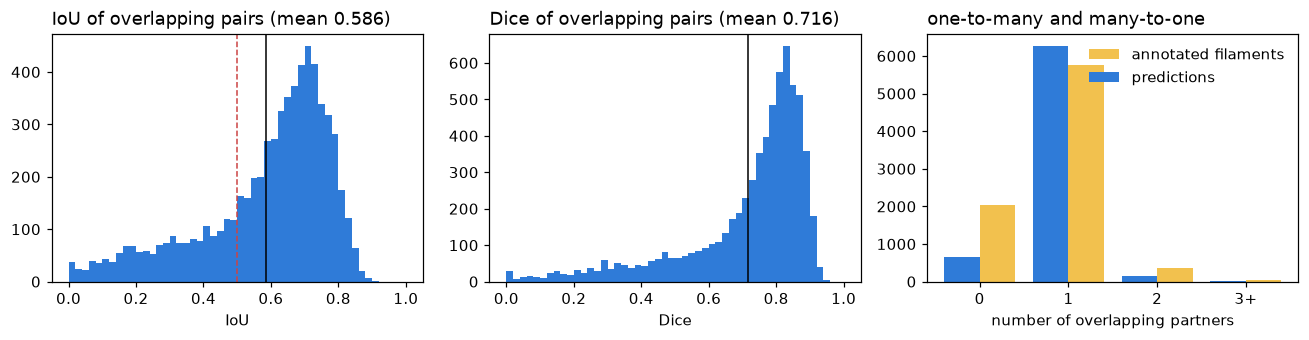

In [7]:
# one annotator scored against the others (images with 2 or 3 annotators)
g = GT.assign(rec=GT["filament_id"].str.rsplit("_", n=1).str[0])
g["annot"], g["stem"] = g["rec"].str.split("-", n=1).str[0], g["rec"].str.split("-", n=1).str[1]
P, Q = [], []
for s, gs in g.groupby("stem"):
    if gs["annot"].nunique() < 2:
        continue
    for a in gs["annot"].unique():
        mine, others = gs[gs["annot"] == a], gs[gs["annot"] != a]
        P += [(f"{s}~{a}_{i + 1}", r) for i, r in enumerate(mine["segmentation_rle"])]
        Q += [(f"{o}-{s}~{a}_{i + 1}", r) for i, (o, r) in enumerate(zip(others["annot"], others["segmentation_rle"]))]
human = fm.pq_fast(pd.DataFrame(Q, columns=["filament_id", "segmentation_rle"]), pd.DataFrame(P, columns=["filament_id", "segmentation_rle"]))
final_oof = pd.concat([refined[t][refined[t]["filament_id"].str.rsplit("_", n=1).str[0].map(fold_of) == k] for k, t in zip(res3["fold"], res3["threshold"])])
stage3 = fm.pq_fast(GT, final_oof)
summary = pd.DataFrame([
    dict(method="stage-1 maps, threshold 0.35, >= 500 px", pq=fs.pq_of_selection(D, fixed, G)["pq"], sq=np.nan, rq=np.nan),
    dict(method="stage 2: tree + expected IoU + exact selection", pq=stage2.pq, sq=stage2.sq, rq=stage2.rq),
    dict(method="stage 3: + crop refiner", pq=stage3.pq, sq=stage3.sq, rq=stage3.rq),
    dict(method="one annotator vs the others", pq=human.pq, sq=human.sq, rq=human.rq)])
(WORK / "results").mkdir(exist_ok=True)
summary.to_csv(WORK / "results" / "notebook_summary.csv", index=False)
print(summary.round(4).to_string(index=False))

st = fm.overlap_stats(GT, final_oof)
final_oof.to_parquet(WORK / "results" / "final_oof_masks.parquet", index=False)
np.savez(WORK / "results" / "overlap_stats.npz", **st)
fig, axs = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, key, name in ((axs[0], "iou", "IoU"), (axs[1], "dice", "Dice")):
    ax.hist(st[key], bins=50, range=(0, 1), color="#2f7bd8")
    ax.axvline(st[key].mean(), color="k", lw=1)
    ax.set_title(f"{name} of overlapping pairs (mean {st[key].mean():.3f})", loc="left")
    ax.set_xlabel(name)
axs[0].axvline(0.5, color="#c44", lw=1, ls="--")
deg_gt = np.bincount(np.minimum(st["gt_degree"], 3), minlength=4)
deg_pr = np.bincount(np.minimum(st["pred_degree"], 3), minlength=4)
axs[2].bar(np.arange(4) + 0.2, deg_gt, 0.4, label="annotated filaments", color="#f2c14e")
axs[2].bar(np.arange(4) - 0.2, deg_pr, 0.4, label="predictions", color="#2f7bd8")
axs[2].set_xticks(range(4))
axs[2].set_xticklabels(["0", "1", "2", "3+"])
axs[2].set_xlabel("number of overlapping partners")
axs[2].legend(frameon=False)
axs[2].set_title("one-to-many and many-to-one", loc="left")
plt.tight_layout()
plt.show()

<cell 8>:20: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


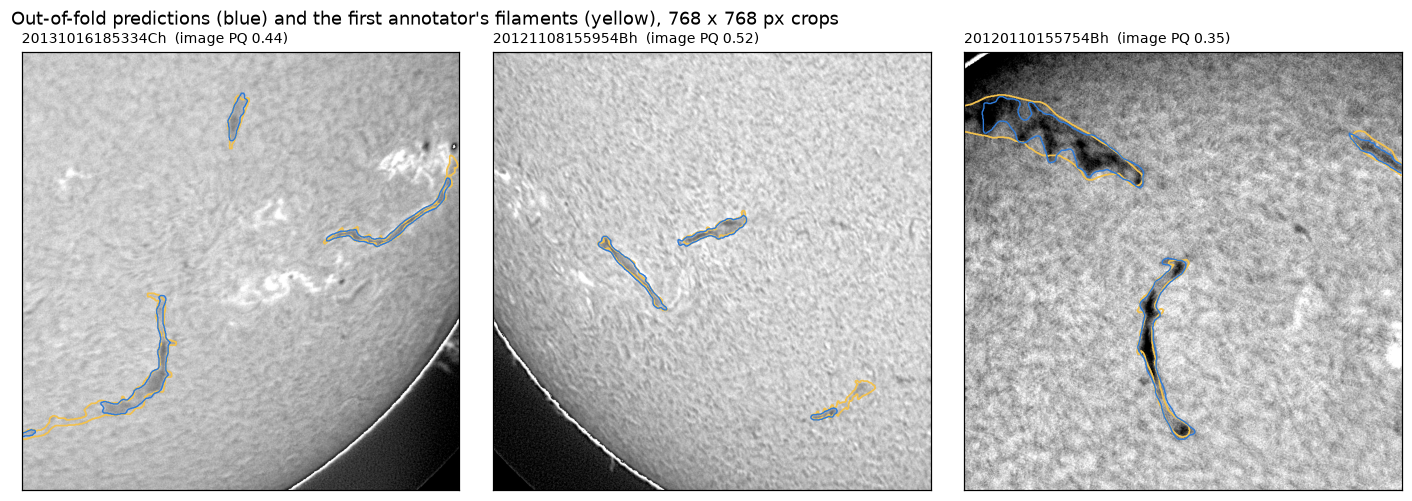

In [8]:
from PIL import Image
per_img = plots.per_image_pq(stage3.per_pair)
order = per_img.sort_values().index
picks = [order[int(q * (len(order) - 1))] for q in (0.5, 0.75, 0.25)]
pred_stem = final_oof["filament_id"].str.rsplit("_", n=1).str[0]
examples = {}
fig, axs = plt.subplots(1, 3, figsize=(13, 4.6))
for ax, s in zip(axs, picks):
    img = np.asarray(Image.open(Path(C.train_dir) / f"{s}.jpeg").convert("L"))
    rec = C.recs_by_stem[s][0]
    gtm = plots.decode(GT.loc[GT["filament_id"].str.startswith(rec + "_"), "segmentation_rle"])
    prm = plots.decode(final_oof.loc[pred_stem == s, "segmentation_rle"])
    r0, c0 = plots.overlay(ax, img, gtm, prm)
    ax.set_title(f"{s}  (image PQ {per_img[s]:.2f})", loc="left", fontsize=9)
    lab = lambda ms: sum((i + 1) * m[r0:r0 + 768, c0:c0 + 768].astype(np.int16) for i, m in enumerate(ms)) if ms else np.zeros((768, 768), np.int16)
    examples[s] = dict(img=img[r0:r0 + 768, c0:c0 + 768], gt=lab(gtm), pred=lab(prm), pq=float(per_img[s]), r0=r0, c0=c0)
fig.suptitle("Out-of-fold predictions (blue) and the first annotator's filaments (yellow), 768 x 768 px crops", x=0.01, ha="left")
pickle.dump(examples, open(WORK / "results" / "examples.pkl", "wb"))
plt.tight_layout()
plt.show()

In [9]:
t0 = time.time()
meta_test = pd.read_parquet(S3 / "refined_test_meta.parquet")
probs_test = np.load(S3 / "refined_test.npz")["probs"]
submission = frf.apply(meta_test, probs_test, [T_FINAL], workers=NW)[T_FINAL]
checks = fm.check_submission(submission)
assert checks["empty"] == 0 and checks["images_with_overlap"] == 0
submission.to_csv(WORK / "submission.csv", index=False)
if ON_KAGGLE:
    submission.to_csv("/kaggle/working/submission.csv", index=False)
print("submission (stage 3):", checks, f"| {time.time() - t0:.0f}s")
print("stage-2 submission without the refiner:", WORK / "submission_stage2.csv")

submission (stage 3): {'rows': 1066, 'images': 175, 'empty': 0, 'images_with_overlap': 0} | 16s
stage-2 submission without the refiner: <root>\work\submission_stage2.csv
